<a href="https://colab.research.google.com/github/yilinw762/ds2002-fa26/blob/main/notebooks/07-visualization/2026-11-13%20%E2%80%94%20Visualization%20Challenge%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

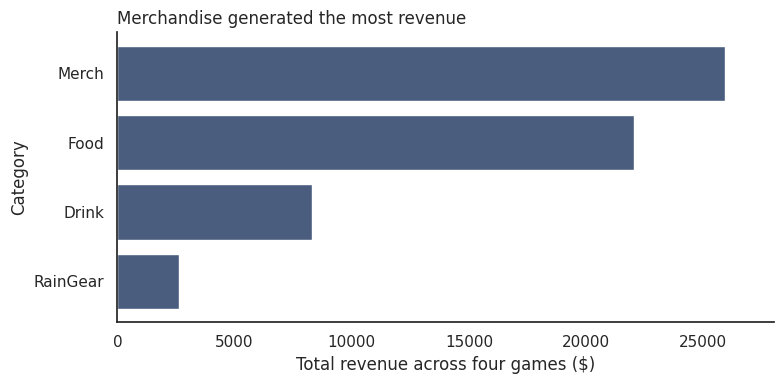

In [2]:
# TODO
category_revenue = (
    df.groupby('category')['revenue']
      .sum()
      .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(category_revenue.index, category_revenue.values, color=BLUE)
finish(
    ax,
    'Merchandise generated the most revenue',
    xlabel='Total revenue across four games ($)',
    ylabel='Category'
)
ax.set_xlim(0, category_revenue.max() * 1.08)
plt.show()

**Caption:** Merchandise leads total revenue, so managers should prioritize merch inventory and staffing when planning sales operations

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

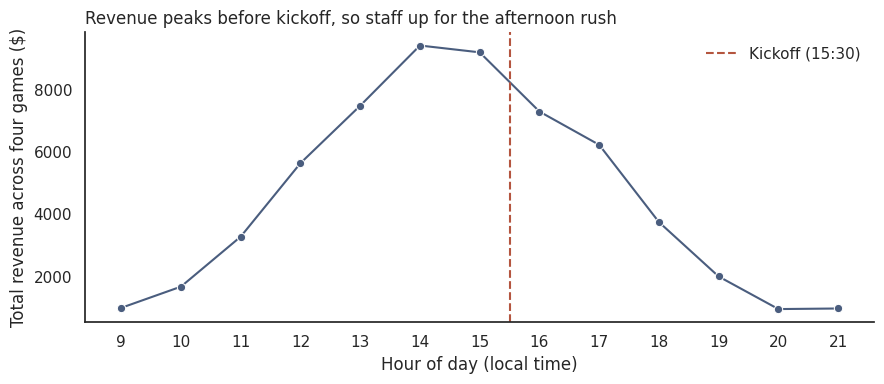

In [3]:
# TODO
hourly_revenue = (
    df.groupby('hour', as_index=False)['revenue']
      .sum()
)

fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(
    data=hourly_revenue,
    x='hour',
    y='revenue',
    marker='o',
    color=BLUE,
    ax=ax
)
ax.axvline(15.5, color=RUST, linestyle='--', label='Kickoff (15:30)')
ax.set_xticks(hours)
finish(
    ax,
    'Revenue peaks before kickoff, so staff up for the afternoon rush',
    xlabel='Hour of day (local time)',
    ylabel='Total revenue across four games ($)'
)
ax.legend(frameon=False)
plt.show()

**Caption:** The 13:00–15:00 window has the highest revenue, supporting heavier staffing before kickoff

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

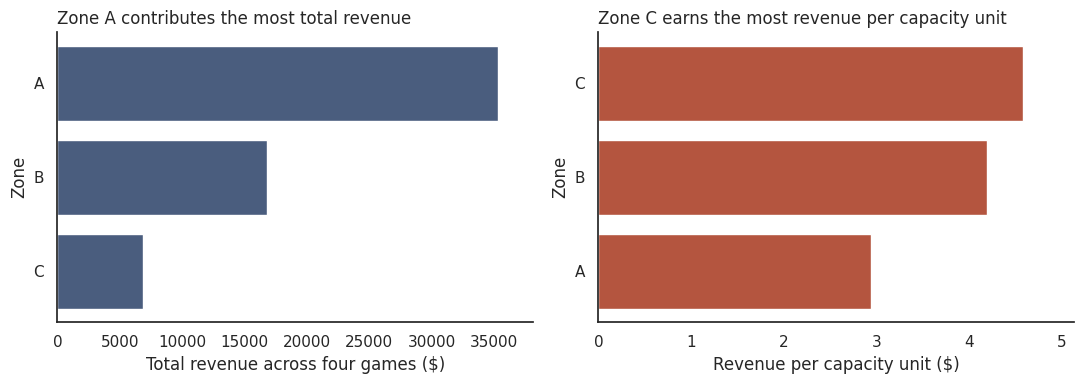

In [4]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
# TODO: two panels -- raw revenue and revenue per capacity
zone_revenue = df.groupby('zone')['revenue'].sum()
capacity = pd.Series(zone_capacity)
revenue_per_capacity = zone_revenue / capacity

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

raw_sorted = zone_revenue.sort_values()
axes[0].barh(raw_sorted.index, raw_sorted.values, color=BLUE)
finish(
    axes[0],
    'Zone A contributes the most total revenue',
    xlabel='Total revenue across four games ($)',
    ylabel='Zone'
)
axes[0].set_xlim(0, raw_sorted.max() * 1.08)

normalized_sorted = revenue_per_capacity.sort_values()
axes[1].barh(normalized_sorted.index, normalized_sorted.values, color=RUST)
finish(
    axes[1],
    'Zone C earns the most revenue per capacity unit',
    xlabel='Revenue per capacity unit ($)',
    ylabel='Zone'
)
axes[1].set_xlim(0, normalized_sorted.max() * 1.12)

fig.tight_layout()
plt.show()

**Caption, and which panel I would present:** I’d show the raw revenue panel when deciding where the largest sales operation is needed; I’d show revenue per capacity unit when comparing how efficiently zones use their capacity.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

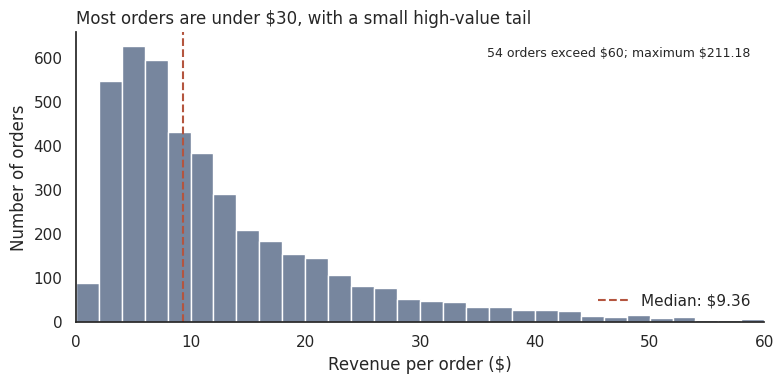

In [5]:
# TODO
fig, ax = plt.subplots(figsize=(8, 4))

visible_orders = df.loc[df['revenue'] <= 60, 'revenue']
sns.histplot(
    visible_orders,
    bins=np.arange(0, 62, 2),
    color=BLUE,
    ax=ax
)

median_revenue = df['revenue'].median()
ax.axvline(
    median_revenue,
    color=RUST,
    linestyle='--',
    label=f'Median: ${median_revenue:.2f}'
)
ax.text(
    0.98, 0.95,
    f'{(df["revenue"] > 60).sum()} orders exceed $60; maximum ${df["revenue"].max():.2f}',
    transform=ax.transAxes,
    ha='right',
    va='top',
    fontsize=9
)
ax.set_xlim(0, 60)
finish(
    ax,
    'Most orders are under $30, with a small high-value tail',
    xlabel='Revenue per order ($)',
    ylabel='Number of orders'
)
ax.legend(frameon=False)
plt.show()

**Caption:** The distribution shows that typical orders are much smaller than the highest-value orders, which helps managers plan for both everyday transactions and occasional large purchases.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

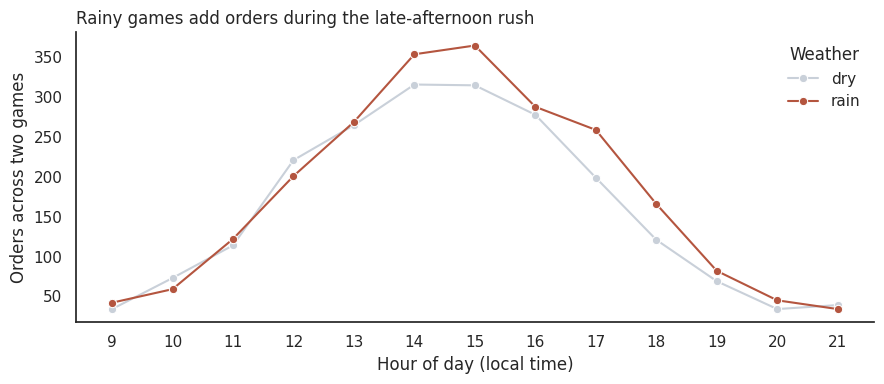

In [6]:
# TODO
hourly_orders = (
    df.groupby(['weather', 'hour'])
      .size()
      .rename('orders')
      .reset_index()
)

fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(
    data=hourly_orders,
    x='hour',
    y='orders',
    hue='weather',
    hue_order=['dry', 'rain'],
    palette={'dry': GRAY, 'rain': RUST},
    marker='o',
    errorbar=None,
    ax=ax
)
ax.set_xticks(hours)
finish(
    ax,
    'Rainy games add orders during the late-afternoon rush',
    xlabel='Hour of day (local time)',
    ylabel='Orders across two games'
)
ax.legend(title='Weather', frameon=False)
plt.show()

**Caption:** Rainy games have more orders around 17:00–19:00, supporting extra late-afternoon service capacity on rainy game days.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
scores = {
    'chart 1 (category)': 6,
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 6,
}

for name, s in scores.items():
    status = 'fix' if s < 5 else 'ok'
    print(f'{name:<26} {s}/6  [{status}]')

print(f'\naverage: {sum(scores.values()) / len(scores):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      6/6  [ok]

average: 6.0/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

a) Chart 4 changed how I read the revenue totals. A total can make a category look successful, but the histogram shows that most individual orders are modest and a small number are much larger. That matters when planning for typical transactions as well as high-value ones.

b) The raw zone revenue panel is right for deciding where to allocate total resources, since it shows which zone contributes the most dollars. The revenue-per-capacity panel is right for comparing efficiency, since it accounts for the different capacities. Zone A leads in total revenue, while Zone C leads per capacity unit.